In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Formation plot

[[-0.7  -0.45  0.    0.45  0.7  -0.35  0.35  0.  ]
 [-0.15 -0.38 -0.5  -0.38 -0.15  0.3   0.3   0.05]]


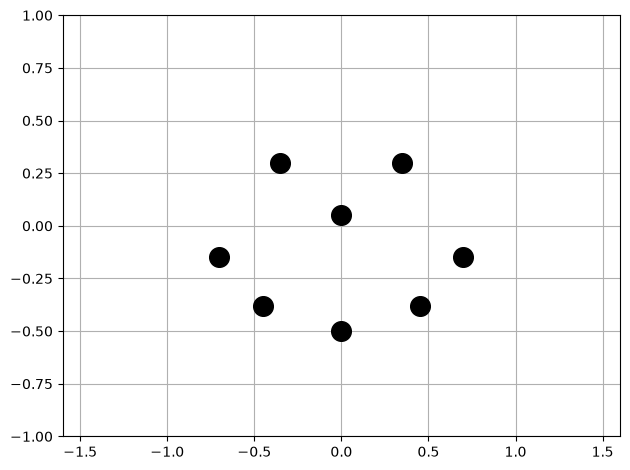

In [120]:
x = np.array([[-0.65, -0.325, 0.00, 0.325, 0.65, -0.35, 0.35, 0.00],
    [-0.15, -0.30, -0.35, -0.30, -0.15, 0.25, 0.25, 0.05]])
x = np.array([[-0.7, -0.45, 0.00, 0.45, 0.7, -0.35, 0.35, 0.00],
              [-0.15, -0.38, -0.5, -0.38, -0.15, 0.3, 0.3, 0.05]])
print(x)
fig, ax = plt.subplots(1,1,layout='tight')
ax.grid()
ax.set_axisbelow(True)
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)
for i in range(len(x[0,:])):
    ax.scatter(x[0,i],x[1,i],s=200,color='black')
plt.show()

# Comm. graph

Adjacency matrix:
[[0 1 1 0 0 1 0 0]
 [1 0 1 1 0 1 0 0]
 [1 1 0 1 1 0 0 1]
 [0 1 1 0 1 0 1 0]
 [0 0 1 1 0 0 1 0]
 [1 1 0 0 0 0 1 1]
 [0 0 0 1 1 1 0 1]
 [0 0 1 0 0 1 1 0]]
[[0.         0.33970576 0.78262379 0.         0.         0.57008771
  0.         0.        ]
 [0.         0.         0.46572524 0.9        0.         0.68731361
  0.         0.        ]
 [0.         0.         0.         0.46572524 0.78262379 0.
  0.         0.55      ]
 [0.         0.         0.         0.         0.33970576 0.
  0.68731361 0.        ]
 [0.         0.         0.         0.         0.         0.
  0.57008771 0.        ]
 [0.         0.         0.         0.         0.         0.
  0.7        0.43011626]
 [0.         0.         0.         0.         0.         0.
  0.         0.43011626]
 [0.         0.         0.         0.         0.         0.
  0.         0.        ]]


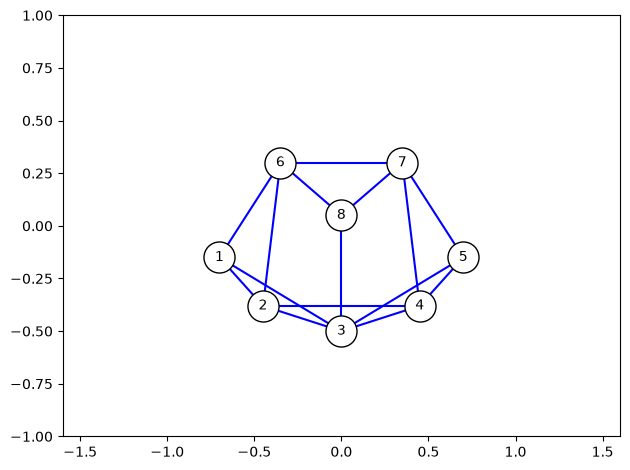

In [ ]:
# adjacency_mat = np.zeros((x.shape[1],x.shape[1]))
# for i in range(-1,len(adjacency_mat)-1):
#     adjacency_mat[i,i+1] = 1
# #     adjacency_mat[1,i+1] = 1
# # adjacency_mat[1,1] = 0; adjacency_mat[1,0] = 0
# #adjacency_mat [1,1] = 0
# adjacency_mat[0,6] = 1
# adjacency_mat[1,5] = 1; adjacency_mat[1,6] = 1
# adjacency_mat[2,4] = 1; adjacency_mat[2,5] = 1
# adjacency_mat[3,7] = 1
# adjacency_mat = adjacency_mat + adjacency_mat.transpose()
# # print(adjacency_mat)


# Initialize adjacency matrix
adjacency_mat = np.zeros((8, 8), dtype=int)
distance_mat = np.zeros((8,8))

# Define undirected communication edges
edges = [
    # Smile (robots 1-5)
    (1, 2),
    (2, 3),
    (3, 4),
    (4, 5),
    (1, 3),
    (2, 4),
    (3, 5),

    # Eyes (robots 6-7)
    (1, 6),
    (2, 6),
    (4, 7),
    (5, 7),
    (6, 7),

    # Nose (robot 8)
    (3, 8),
    (6, 8),
    (7, 8)
]

# Populate adjacency matrix
for i, j in edges:
    adjacency_mat[i-1, j-1] = 1
    adjacency_mat[j-1, i-1] = 1

print("Adjacency matrix:")
print(adjacency_mat)

fig, ax = plt.subplots(1,1,layout='tight')
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)
for i in range(adjacency_mat.shape[0]):
    for j in range(i,adjacency_mat.shape[1]):
        if adjacency_mat[i,j] == 1:
            distance_mat[i,j] = np.linalg.norm(x[:,i]-x[:,j])
            ax.plot([x[0,i],x[0,j]],[x[1,i],x[1,j]],zorder=1,color='blue')
distance_mat = distance_mat + distance_mat.transpose()
for i in range(x.shape[1]):
    ax.scatter(x[0,i],x[1,i],s=500,facecolors='white',edgecolors='black',zorder=2)
    ax.text(x[0,i],x[1,i],s=str(i+1),ha='center',va='center')
print(distance_mat)
plt.show()


## Laplacian

In [102]:
L = np.diag(np.sum(adjacency_mat, axis=1)) - adjacency_mat
print(L)

[[ 3. -1. -1.  0.  0.  0.  0. -1.]
 [-1.  7. -1. -1. -1. -1. -1. -1.]
 [-1. -1.  3. -1.  0.  0.  0.  0.]
 [ 0. -1. -1.  3. -1.  0.  0.  0.]
 [ 0. -1.  0. -1.  3. -1.  0.  0.]
 [ 0. -1.  0.  0. -1.  3. -1.  0.]
 [ 0. -1.  0.  0.  0. -1.  3. -1.]
 [-1. -1.  0.  0.  0.  0. -1.  3.]]
